# Milestone 2, Section 3: efficiency of training and inference

Measures the cost of the two same-story models from Section 2:

- **bi-encoder**: the fine-tuned MiniLM (`models/minilm_finetuned`, `milestone2_training.ipynb`). Each headline becomes a vector, a pair's score is the cosine of the two vectors.
- **cross-encoder**: the mMiniLM cross-encoder (`models/exp/cross_encoder`, `milestone2_experiments.ipynb`). It reads both headlines together, once in each order, and averages the two probabilities.

1. Setup and hardware
2. Training efficiency (3.1): time, memory, model size, FLOPs, energy
3. Inference efficiency (3.2): latency p50/p90, throughput, memory
4. Optimization attempts: ONNX export, int8 quantization, Apple GPU, with their effect on latency and accuracy
5. Summary

The training numbers for the real runs come from the RTX 3080 machine (`outputs/milestone2/training_efficiency.csv` and `outputs/milestone2/experiments/log.csv`). Everything else is measured here, on the machine described in Section 1. The measuring code is in `src/m2_efficiency.py`. Every measurement runs in a fresh Python process so memory numbers do not mix between models. Outputs go to `outputs/milestone2/efficiency/`.

The models are not in git (too large). Put the shared folders at `models/minilm_finetuned` and `models/exp/cross_encoder` before running.

In [1]:
import json, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'milestone2' / 'efficiency'
OUT.mkdir(parents=True, exist_ok=True)
M2 = ROOT / 'outputs' / 'milestone2'

def run(*args):
    """One measurement in a fresh process; returns the result dict printed by src/m2_efficiency.py."""
    p = subprocess.run([sys.executable, '-m', 'src.m2_efficiency', *args], cwd=ROOT, capture_output=True, text=True)
    line = next((l for l in p.stdout.splitlines() if l.startswith('RESULT ')), None)
    if line is None:
        raise RuntimeError(p.stderr[-3000:])
    return json.loads(line[len('RESULT '):])

pd.set_option('display.max_colwidth', 80)

## 1. Setup and hardware

In [2]:
import platform, psutil, torch, transformers, onnxruntime
from src.m2_efficiency import hardware, PATHS

HARDWARE = {**hardware('cpu'), 'gpu': 'Apple GPU via PyTorch MPS' if torch.backends.mps.is_available() else 'none',
            'os': platform.platform(), 'python': platform.python_version(), 'transformers': transformers.__version__,
            'onnxruntime': onnxruntime.__version__}
json.dump(HARDWARE, open(OUT / 'hardware.json', 'w'), indent=2)
HARDWARE

{'cpu': 'Apple M4 Max',
 'torch threads': 10,
 'ram_gb': 38.7,
 'gpu': 'Apple GPU via PyTorch MPS',
 'torch': '2.8.0',
 'os': 'macOS-26.6.2-arm64-arm-64bit',
 'python': '3.9.6',
 'transformers': '4.57.6',
 'onnxruntime': '1.19.2'}

## 2. Training efficiency (3.1)

**Real training runs (RTX 3080).** The bi-encoder numbers are the ones recorded during the main run in `milestone2_training.ipynb`. For the cross-encoder, only the total time was logged (`outputs/milestone2/experiments/log.csv`). It ran 2 epochs: the best epoch was 1, then early stopping with patience 1.

**FLOPs.** PyTorch's `FlopCounterMode` counts the matrix multiplications of real batches (a multiply-add counts as 2 FLOPs). For training it counts forward + backward + the update for 10 batches of 32 training pairs, with the padding a real batch has. Total = FLOPs per pair × 21,907 training pairs × 2 epochs, plus scoring the 2,850 val pairs after each epoch.

**Same-machine comparison (Apple M4 Max GPU).** The cross-encoder run on the 3080 did not record steps/s or memory. So both models are trained here for 60 steps with the real recipe (batch 32, AdamW, same loss), and the steps after the first 10 are timed. This gives the cost per step of the two models on the same hardware. It is not a replacement for the 3080 numbers.

In [3]:
flops = {m: run('flops', '--model', m) for m in ['bi', 'cross']}
local_train = {m: run('train', '--model', m, '--device', 'mps') for m in ['bi', 'cross']}
pd.DataFrame(local_train).drop('hardware')

,bi,cross
model,bi,cross
device,mps,mps
steps timed,50,50
batch size,32,32
steps per second,12.03,7.34
train FLOPs per pair (GFLOPs),3.022,2.729
total parameters,117653760,117641089
trainable parameters,21639552,117641089
peak RSS (MB),1348,5372
"peak GPU tensor memory, MPS (MB)",3019,3815


In [4]:
bi_3080 = pd.read_csv(M2 / 'training_efficiency.csv', index_col=0)['value']
log = pd.read_csv(M2 / 'experiments' / 'log.csv').set_index('name')
cfg = json.load(open(M2 / 'train_config.json'))
TRAIN_PAIRS, VAL_PAIRS, EPOCHS = int(log.loc['v1', 'train_pairs']), 2850, 2
size_mb = lambda p: sum(f.stat().st_size for f in Path(p).resolve().rglob('*') if f.is_file()) / 1e6

def total_flops(m):
    train = local_train[m]['train FLOPs per pair (GFLOPs)'] * TRAIN_PAIRS * EPOCHS
    val = flops[m]['forward FLOPs per pair (GFLOPs)'] * VAL_PAIRS * EPOCHS
    return train, val

rows = {}
for m, name in [('bi', 'bi-encoder (MiniLM, fine-tuned)'), ('cross', 'cross-encoder (mMiniLM)')]:
    train_gf, val_gf = total_flops(m)
    minutes = float(bi_3080['total training time (min)']) if m == 'bi' else float(log.loc['cross_encoder', 'train_minutes'])
    rows[name] = {
        'hardware (real run)': f"{cfg['hardware']['gpu']}, batch 32",
        'epochs run': EPOCHS,
        'total training time (min)': minutes,
        'time per epoch (min)': round(minutes / EPOCHS, 2),
        'steps per second (RTX 3080)': float(bi_3080['steps per second']) if m == 'bi' else 'not recorded',
        'peak GPU memory, RTX 3080 (GB)': float(bi_3080['peak GPU memory (GB)']) if m == 'bi' else 'not recorded',
        'steps per second (M4 Max GPU, same recipe)': local_train[m]['steps per second'],
        'peak GPU tensor memory, M4 Max (GB)': round(local_train[m]['peak GPU tensor memory, MPS (MB)'] / 1000, 2),
        'total parameters (M)': round(local_train[m]['total parameters'] / 1e6, 1),
        'trainable parameters (M)': round(local_train[m]['trainable parameters'] / 1e6, 1),
        'model size on disk (MB)': round(size_mb(PATHS[m]), 1),
        'training FLOPs per pair (GFLOPs, fwd+bwd)': local_train[m]['train FLOPs per pair (GFLOPs)'],
        'total training FLOPs (PFLOPs)': round((train_gf + val_gf) / 1e6, 2),
        'energy, upper bound at 320 W (Wh)': round(320 * minutes / 60, 1),
    }
training = pd.DataFrame(rows)
training.to_csv(OUT / 'training_efficiency.csv')
training

,"bi-encoder (MiniLM, fine-tuned)",cross-encoder (mMiniLM)
hardware (real run),"NVIDIA GeForce RTX 3080, batch 32","NVIDIA GeForce RTX 3080, batch 32"
epochs run,2,2
total training time (min),1.5,1.34
time per epoch (min),0.75,0.67
steps per second (RTX 3080),16.68,not recorded
"peak GPU memory, RTX 3080 (GB)",1.83,not recorded
"steps per second (M4 Max GPU, same recipe)",12.03,7.34
"peak GPU tensor memory, M4 Max (GB)",3.02,3.81
total parameters (M),117.7,117.6
trainable parameters (M),21.6,117.6


Notes:

- **Trainable parameters:** the bi-encoder keeps its 96M-parameter word-embedding table frozen, so only 21.6M of its 117.7M parameters are trained. The cross-encoder trains all of them, because it was fine-tuned from `mmarco-mMiniLMv2` without freezing. Most of each model (96M of 118M parameters) is the 250k-word multilingual vocabulary table. A table lookup costs almost no FLOPs, so the compute comes from the 21M parameters in the 12 transformer layers.
- **Energy:** an upper bound, assuming the RTX 3080 draws its full 320 W board power for the whole run. Under 10 Wh per model, which costs less than $0.01 of electricity. Training cost does not matter for this project. Inference cost does, because the extension scores every page a user opens.

## 3. Inference efficiency (3.2)

**Sample** = one headline pair → one same-story score, which is the unit both models output. Both models read 2 sequences per pair: the bi-encoder reads the two headlines separately, the cross-encoder reads the pair once in each order. Timings include tokenization and run from the raw strings to the score.

- **Per-sample latency:** 300 random test pairs scored one at a time (batch size 1), after 20 warm-up calls.
- **Batch latency and throughput:** the 2,457 test pairs in batches of 64 pairs.
- **One front page:** the realistic call from the extension. All pairs on one Google News front page (Top stories / À la une), for the 112 test-period pages, about 9 headlines each. The bi-encoder embeds each headline once and takes all cosines from that. The cross-encoder needs a forward pass for every pair (≈36 pairs × 2 orders).
- **Memory:** process RSS before loading, after loading, and the peak over the whole run (`ru_maxrss`). For the Apple GPU, the PyTorch tensor memory on it as well (`torch.mps.current_allocated_memory`, sampled right after each forward pass). On Apple Silicon the CPU and GPU share the same RAM.
- **Accuracy:** for every variant the threshold is picked on val and applied unchanged to test, the same rule as `baselines.py`.

Grid: both models × {PyTorch fp32 on CPU, PyTorch fp32 on the Apple GPU (MPS), PyTorch dynamic int8 on CPU, ONNX Runtime fp32 on CPU, ONNX Runtime dynamic int8 on CPU}. CPU runs use 10 threads.

In [5]:
export = {m: run('export', '--model', m) for m in ['bi', 'cross']}   # writes models/onnx/{bi,cross}_{fp32,int8}.onnx
GRID = [('torch', 'cpu'), ('torch', 'mps'), ('torch_int8', 'cpu'), ('onnx', 'cpu'), ('onnx_int8', 'cpu')]
results = [run('infer', '--model', m, '--backend', b, '--device', d) for m in ['bi', 'cross'] for b, d in GRID]
json.dump({'export': export, 'flops': flops, 'local_train': local_train, 'infer': results}, open(OUT / 'raw_results.json', 'w'), indent=2)

LABEL = {'torch': 'PyTorch fp32', 'torch_int8': 'PyTorch int8 (dynamic)', 'onnx': 'ONNX Runtime fp32', 'onnx_int8': 'ONNX Runtime int8 (dynamic)'}
MODEL = {'bi': 'bi-encoder', 'cross': 'cross-encoder'}
inf = pd.DataFrame(results).drop(columns='hardware')
inf.insert(0, 'variant', [f"{LABEL[b]}, {'Apple GPU (MPS)' if d == 'mps' else 'CPU'}" for b, d in zip(inf.backend, inf.device)])
inf['model'] = inf.model.map(MODEL)
inf.to_csv(OUT / 'inference_all.csv', index=False)

### Baseline: PyTorch fp32 on the CPU and on the Apple GPU

In [6]:
cols = ['model', 'variant', 'latency p50, 1 pair (ms)', 'latency p90, 1 pair (ms)',
        'latency p50, batch of 64 pairs (ms)', 'latency p90, batch of 64 pairs (ms)', 'throughput, batch 64 (pairs/s)',
        'latency p50, one front page (ms)', 'latency p90, one front page (ms)',
        'RSS after loading (MB)', 'peak RSS (MB)', 'peak GPU tensor memory, MPS (MB)']
base = inf[inf.backend == 'torch'][cols].set_index(['model', 'variant'])
base['FLOPs per pair (GFLOPs)'] = [flops['bi' if 'bi' in m else 'cross']['forward FLOPs per pair (GFLOPs)'] for m, _ in base.index]
base.to_csv(OUT / 'inference_efficiency.csv')
base.T

model                                      bi-encoder  \
variant                             PyTorch fp32, CPU   
latency p50, 1 pair (ms)                         7.55   
latency p90, 1 pair (ms)                         8.47   
latency p50, batch of 64 pairs (ms)            114.05   
latency p90, batch of 64 pairs (ms)            137.20   
throughput, batch 64 (pairs/s)                 540.10   
latency p50, one front page (ms)                16.23   
latency p90, one front page (ms)                18.62   
RSS after loading (MB)                         801.00   
peak RSS (MB)                                 1274.00   
peak GPU tensor memory, MPS (MB)                  NaN   
FLOPs per pair (GFLOPs)                          2.10   

model                                                              \
variant                             PyTorch fp32, Apple GPU (MPS)   
latency p50, 1 pair (ms)                                     7.10   
latency p90, 1 pair (ms)                                    10.34   
latency p50, batch of 64 pairs (ms)                         39.48   
latency p90, batch of 64 pairs (ms)                         58.97   
throughput, batch 64 (pairs/s)                            1350.00   
latency p50, one front page (ms)                             9.58   
latency p90, one front page (ms)                            32.52   
RSS after loading (MB)                                     805.00   
peak RSS (MB)                                             1373.00   
peak GPU tensor memory, MPS (MB)                           499.00   
FLOPs per pair (GFLOPs)                                      2.10   

model                                   cross-encoder  \
variant                             PyTorch fp32, CPU   
latency p50, 1 pair (ms)                       12.250   
latency p90, 1 pair (ms)                       15.530   
latency p50, batch of 64 pairs (ms)           293.210   
latency p90, batch of 64 pairs (ms)           342.920   
throughput, batch 64 (pairs/s)                213.400   
latency p50, one front page (ms)              121.800   
latency p90, one front page (ms)              156.830   
RSS after loading (MB)                        802.000   
peak RSS (MB)                                1784.000   
peak GPU tensor memory, MPS (MB)                  NaN   
FLOPs per pair (GFLOPs)                         3.688   

model                                                              
variant                             PyTorch fp32, Apple GPU (MPS)  
latency p50, 1 pair (ms)                                    9.150  
latency p90, 1 pair (ms)                                   29.460  
latency p50, batch of 64 pairs (ms)                        75.180  
latency p90, batch of 64 pairs (ms)                        99.690  
throughput, batch 64 (pairs/s)                            700.300  
latency p50, one front page (ms)                           51.560  
latency p90, one front page (ms)                           86.370  
RSS after loading (MB)                                    805.000  
peak RSS (MB)                                            1755.000  
peak GPU tensor memory, MPS (MB)                          471.000  
FLOPs per pair (GFLOPs)                                     3.688

## 4. Optimization attempts

The two models were exported to ONNX (opset 17, dynamic batch and sequence length) and run with ONNX Runtime. Each ONNX graph was also quantized with ONNX Runtime **dynamic int8 quantization**: the weights, including the vocabulary table, are stored as int8, and activations are quantized on the fly. PyTorch's own dynamic int8 quantization of the `Linear` layers is included for comparison. Accuracy is re-measured for every variant with its own val-picked threshold.

Distillation was not tried. Both models are already 12-layer, 384-dim MiniLMs distilled from larger models, and the time left in this milestone went to the measurements above.

In [7]:
ref = inf[(inf.backend == 'torch') & (inf.device == 'cpu')].set_index('model')
size = {('bi', 'torch'): size_mb(PATHS['bi']), ('cross', 'torch'): size_mb(PATHS['cross'])}
for m in ['bi', 'cross']:
    size[(m, 'onnx')], size[(m, 'onnx_int8')] = export[m]['onnx fp32 (MB)'], export[m]['onnx int8 (MB)']
opt = inf.copy()
key = {'bi-encoder': 'bi', 'cross-encoder': 'cross'}
opt['size on disk (MB)'] = [round(size.get((key[m], b), np.nan), 1) for m, b in zip(opt.model, opt.backend)]
for c, new in [('latency p50, 1 pair (ms)', 'speed-up, 1 pair'), ('throughput, batch 64 (pairs/s)', 'speed-up, batch 64'),
               ('latency p50, one front page (ms)', 'speed-up, front page')]:
    r = opt.model.map(ref[c])
    opt[new] = (r / opt[c] if 'throughput' not in c else opt[c] / r).round(2)
opt['F1 change vs fp32 CPU'] = (opt['test F1'] - opt.model.map(ref['test F1'])).round(4)
opt_cols = ['model', 'variant', 'latency p50, 1 pair (ms)', 'latency p90, 1 pair (ms)', 'throughput, batch 64 (pairs/s)',
            'latency p50, one front page (ms)', 'speed-up, 1 pair', 'speed-up, batch 64', 'speed-up, front page',
            'peak RSS (MB)', 'size on disk (MB)', 'test F1', 'F1 change vs fp32 CPU', 'test PR-AUC']
optimization = opt[opt_cols]
optimization.to_csv(OUT / 'optimization.csv', index=False)
optimization

,model,variant,"latency p50, 1 pair (ms)","latency p90, 1 pair (ms)","throughput, batch 64 (pairs/s)","latency p50, one front page (ms)","speed-up, 1 pair","speed-up, batch 64","speed-up, front page",peak RSS (MB),size on disk (MB),test F1,F1 change vs fp32 CPU,test PR-AUC
0,bi-encoder,"PyTorch fp32, CPU",7.55,8.47,540.1,16.23,1.00,1.00,1.00,1274,487.7,0.9059,0.0000,0.9658
1,bi-encoder,"PyTorch fp32, Apple GPU (MPS)",7.10,10.34,1350.0,9.58,1.06,2.50,1.69,1373,487.7,0.9059,0.0000,0.9658
2,bi-encoder,"PyTorch int8 (dynamic), CPU",13.57,15.61,174.2,36.10,0.56,0.32,0.45,1760,NaN,0.9036,-0.0023,0.9655
3,bi-encoder,"ONNX Runtime fp32, CPU",7.10,10.61,211.5,23.47,1.06,0.39,0.69,2468,470.2,0.9059,0.0000,0.9658
4,bi-encoder,"ONNX Runtime int8 (dynamic), CPU",7.17,10.27,244.3,27.05,1.05,0.45,0.60,1499,118.1,0.9028,-0.0031,0.9661
5,cross-encoder,"PyTorch fp32, CPU",12.25,15.53,213.4,121.80,1.00,1.00,1.00,1784,487.7,0.9093,0.0000,0.9637
6,cross-encoder,"PyTorch fp32, Apple GPU (MPS)",9.15,29.46,700.3,51.56,1.34,3.28,2.36,1755,487.7,0.9093,0.0000,0.9637
7,cross-encoder,"PyTorch int8 (dynamic), CPU",39.34,69.51,102.6,393.56,0.31,0.48,0.31,2173,NaN,0.9013,-0.0080,0.9606
8,cross-encoder,"ONNX Runtime fp32, CPU",7.58,9.77,133.4,267.46,1.62,0.63,0.46,2532,470.8,0.9093,0.0000,0.9637
9,cross-encoder,"ONNX Runtime int8 (dynamic), CPU",6.72,9.01,184.8,202.31,1.82,0.87,0.60,1705,118.3,0.9039,-0.0054,0.9603


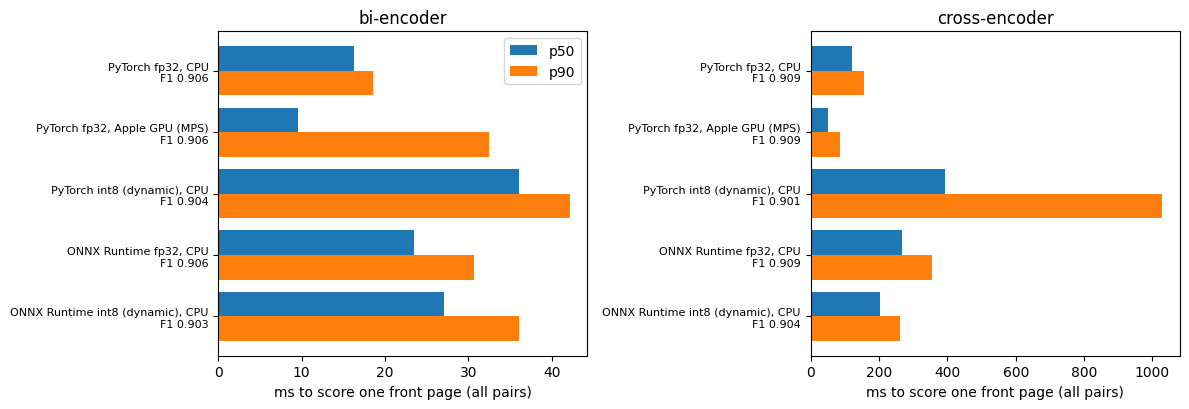

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, m in zip(axes, ['bi-encoder', 'cross-encoder']):
    d = opt[opt.model == m]
    y = np.arange(len(d))
    ax.barh(y - 0.2, d['latency p50, one front page (ms)'], 0.4, label='p50')
    ax.barh(y + 0.2, d['latency p90, one front page (ms)'], 0.4, label='p90')
    ax.set_yticks(y, [f"{v}\nF1 {f:.3f}" for v, f in zip(d.variant, d['test F1'])], fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel('ms to score one front page (all pairs)'); ax.set_title(m)
axes[0].legend()
fig.tight_layout(); fig.savefig(OUT / 'latency_by_variant.png', dpi=150)

## 5. Summary

In [9]:
best = lambda m: opt[opt.model == m].sort_values('latency p50, one front page (ms)').iloc[0]
for m in ['bi-encoder', 'cross-encoder']:
    r, b = ref.loc[m], best(m)
    print(f"{m}: fp32 CPU {r['latency p50, 1 pair (ms)']} ms/pair p50, {r['latency p50, one front page (ms)']} ms/page p50, "
          f"F1 {r['test F1']}; fastest per page: {b.variant} ({b['latency p50, one front page (ms)']} ms, "
          f"F1 {b['test F1']}, {b['size on disk (MB)']} MB)")

bi-encoder: fp32 CPU 7.55 ms/pair p50, 16.23 ms/page p50, F1 0.9059; fastest per page: PyTorch fp32, Apple GPU (MPS) (9.58 ms, F1 0.9059, 487.7 MB)
cross-encoder: fp32 CPU 12.25 ms/pair p50, 121.8 ms/page p50, F1 0.9093; fastest per page: PyTorch fp32, Apple GPU (MPS) (51.56 ms, F1 0.9093, 487.7 MB)


### Findings (numbers from the run above, Apple M4 Max)

- **The bi-encoder is the one to deploy.** On the CPU it scores one pair in 7.6 ms (p50, p90 8.5 ms) and a whole front page in 16 ms (p90 19 ms), or 10 ms on the Apple GPU. The cross-encoder is only 1.6× slower per pair (12.3 ms), but **7.5× slower per front page** (122 ms on the CPU, 52 ms on the GPU). The bi-encoder embeds the ~9 headlines once and gets every cosine from those vectors. The cross-encoder needs a forward pass for each of the ~36 pairs, in both orders. Its accuracy gain does not pay for that. In `final_test.csv` it has the same pair F1 as the bi-encoder (0.906), and it groups 71% vs 67% of Google's cards exactly. Its F1 here is 0.909 only because the val-picked threshold came out slightly different in this run (identical PR-AUC).
- **FLOPs:** 2.1 GFLOPs per pair for the bi-encoder and 3.7 for the cross-encoder at batch 1. Per front page the gap grows with the page size: the bi-encoder's cost is linear in the number of headlines, the cross-encoder's is quadratic.
- **Memory:** about 0.8 GB of RAM once a model is loaded, and a 1.3 to 1.8 GB peak while scoring. On the Apple GPU the model's tensors take about 0.5 GB. The 96M-parameter vocabulary table is most of it.
- **ONNX export:** the scores are the same as PyTorch (same F1 and PR-AUC). At batch size 1 it helps the cross-encoder (7.6 ms vs 12.3 ms per pair, 1.6×) and leaves the bi-encoder unchanged. With larger batches it is 1.4 to 2.6× *slower* than PyTorch on this Mac. This PyTorch build does its large matrix products with Apple's Accelerate library (`BLAS_INFO=accelerate`), which ONNX Runtime's CPU kernels do not use. On an x86 CPU the result may differ.
- **ONNX int8 quantization:** the model file shrinks 4× (470 MB → 118 MB), peak RAM drops by 0.8 to 1 GB versus ONNX fp32, and F1 drops by 0.003 (bi) and 0.005 (cross). It is the fastest CPU variant for single cross-encoder pairs (6.7 ms, 1.8×). It does not speed up batches.
- **PyTorch dynamic int8** (`qnnpack` on ARM) is slower than fp32 in every setting (0.3 to 0.6×) and loses up to 0.008 F1. Not worth keeping.
- **Apple GPU (MPS)** gives the best batch numbers: 2.5× (bi) and 3.3× (cross) throughput over the CPU. For single pairs it does no better and its p90 is worse (more launch overhead per call).
- **Comparison with the 3080 numbers:** `final_test.csv` reports 0.075 s per 1,000 pairs (≈13,000 pairs/s) for the bi-encoder on the RTX 3080. That run embedded each distinct headline only once, on a discrete GPU, so it is not comparable with the per-batch throughput above. Its 10× gap between the two models is close to the 7.5× per-page gap here, because both use the bi-encoder's strength of embedding each headline once.
